# Analyzing an Unbalanced A/B Test: Attributed vs. Incremental Conversions

In [88]:
# Import & Load
# Data source: Kaggle: https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing, saved as data/raw/marketing_AB.csv
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(palette='viridis')

df = pd.read_csv("data/raw/marketing_AB.csv")
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## data cleaning

In [3]:
print(df.shape,"\n")
df.info()

(588101, 7) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


In [4]:
df = df.drop(columns="Unnamed: 0") # drops junk column

In [5]:
df.isna().sum() # checks for missing values

user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

In [6]:
df["user id"].duplicated().sum() # checks for duplciate user id's

0

In [9]:
df.columns.to_list()

['user_id',
 'test_group',
 'converted',
 'total_ads',
 'most_ads_day',
 'most_ads_hour']

In [10]:
# rename columns for ease
df.columns = df.columns.str.replace(" ", "_") 
df.columns.to_list()

['user_id',
 'test_group',
 'converted',
 'total_ads',
 'most_ads_day',
 'most_ads_hour']

In [11]:
df.value_counts(subset='test_group')

test_group
ad     564577
psa     23524
Name: count, dtype: int64

In [12]:
df.value_counts(subset='most_ads_day')

most_ads_day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64

## Group sizes, conversion rates and balance
- how many users are in each group?
- how do the raw conversion rates compare?
- and do the groups look alike on the other columns?

In [17]:
# Summary table
summary = df.groupby("test_group")["converted"].agg([('users','count'), ('conversions', 'sum'), ('rate', 'mean')])
summary['share_of_users'] = summary['users']/summary['users'].sum()
summary

,users,conversions,rate,share_of_users
test_group,,,,
ad,564577,14423,0.025547,0.96
psa,23524,420,0.017854,0.04


In [26]:
# named variables
n_ad = summary.loc["ad", "users"] 
x_ad = summary.loc["ad", "conversions"] 
n_psa = summary.loc["psa", "users"] 
x_psa = summary.loc["psa", "conversions"] 
rate_ad = summary.loc['ad','rate']
rate_psa = summary.loc['psa','rate']

# rate_ad = x_ad / n_ad 
# rate_psa = x_psa / n_psa 

print(f'users in ad group: {n_ad:,}')
print(f'conversions in ad group: {x_ad:,}')
print(f'users in psa group: {n_psa:,}')
print(f'conversions in psa group: {x_psa:,}')
print(f'ad conversion rate: {rate_ad:.2%}')
print(f'psa conversion rate: {rate_psa:.2%}')

users in ad group: 564,577
conversions in ad group: 14,423
users in psa group: 23,524
conversions in psa group: 420
ad conversion rate: 2.55%
psa conversion rate: 1.79%


In [27]:
df.groupby("test_group")["total_ads"].describe() 

,count,mean,std,min,25%,50%,75%,max
test_group,,,,,,,,
ad,564577.0,24.823365,43.750456,1.0,4.0,13.0,27.0,2065.0
psa,23524.0,24.761138,42.860720,1.0,4.0,12.0,26.0,907.0


In [28]:
# contignecy table
pd.crosstab(df["most_ads_day"], df["test_group"], normalize='columns')

test_group,ad,psa
most_ads_day,,
Friday,0.157295,0.161665
Monday,0.148024,0.148869
Saturday,0.139577,0.121493
Sunday,0.145830,0.130037
Thursday,0.140064,0.166001
Tuesday,0.132085,0.123576
Wednesday,0.137126,0.148359


## Lift, z-test and confidence intervals
- lift is the ad conversion rate minus the psa rate 
- z-test asks if a gap this size could just be luck, if the ad actually did nothing
- the CI gives a plausible range for the true lift

In [30]:
# Lift
lift = (rate_ad - rate_psa)  
rel_lift = lift/rate_psa    # relative lift
print(f'lift: {lift* 100:.2} pp')
print(f'relative lift: {rel_lift:.3}%')

lift: 0.77 pp
relative lift: 0.431%


In [33]:
# z-test (two-sided, pooled cuz the null says there is one shared rate)
from statsmodels.stats.proportion import proportions_ztest
z, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa])
print(f'z: {z:.3}')
print(f'p value: {p_value:.2g}') # p < 0.001

z: 7.37
p value: 1.7e-13


In [34]:
# 95% Confidence interval for the lift 
from statsmodels.stats.proportion import confint_proportions_2indep
ci_low, ci_high = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, method="wald")
# analytic, unpooled- estimating the real gap
print(f'CI low : {ci_low}')
print(f'CI high : {ci_high}')

CI low : 0.005950932431611005
CI high : 0.00943397395279203


In [36]:
# CI by hand
# Formula: 
ad_piece = rate_ad * (1 - rate_ad) / n_ad
psa_piece = rate_psa * (1 - rate_psa) / n_psa
SE = np.sqrt(ad_piece + psa_piece)

print(f"Standard Error: {SE * 100:.3f} pp")
print(f"Confidence Interval: {(lift - 1.96*SE)*100:.3f} to {(lift + 1.96*SE)*100:.3f} pp")

Standard Error: 0.089 pp
Confidence Interval: 0.595 to 0.943 pp


- The ad group converted at 2.55% vs 1.79% for the PSA group, a lift of 0.77 
percentage points (about 43.1% relative)
-  The p-value (1.7e-13) tells us that if the ad did nothing, a gap this large would be very very unlikely. 
- The 95% confidence interval of 0.60 to 0.94 pp shows a plausible range of 
the true lift, 
so even a pessimistic plausible lift of 0.60 pp (on the lower end) is still a positive gain. 
The gap between the two ends show how precisely 
we know the true lift.

## Bootstrap
simulating rerunning experiment using the data availabe via the bootstrap resampling method

In [66]:
# data
ad_converted = df[df["test_group"] == "ad"]["converted"].to_numpy(dtype=np.int8)             
psa_converted = df[df["test_group"] == "psa"]["converted"].to_numpy(dtype=np.int8)

In [ ]:
# helper function
def lift_stat(a, b, axis):
    return a.mean(axis=axis) - b.mean(axis=axis) # conversionr rate for resample & psa

In [70]:
from scipy.stats import bootstrap
boot = bootstrap((ad_converted, psa_converted), lift_stat, vectorized=True,
                n_resamples=5000, batch=50, method="percentile", random_state=42)
boot_low, boot_high = boot.confidence_interval

print(f'bootstrap low: {boot_low * 100:.3f} pp')
print(f'bootstrap high: {boot_high *100:.3f} pp')

bootstrap low: 0.593 pp
bootstrap high: 0.941 pp


The bootstrap confidence interval (0.593 to 0.941) and the formual interval (0.595 to 0.943) are almost identical. The formula's assumed that lift would vary in a bell shaped pattern accross repeated experiments, and the boostrap, which makes no such assumtion gives the same answer so the assumption holds. 

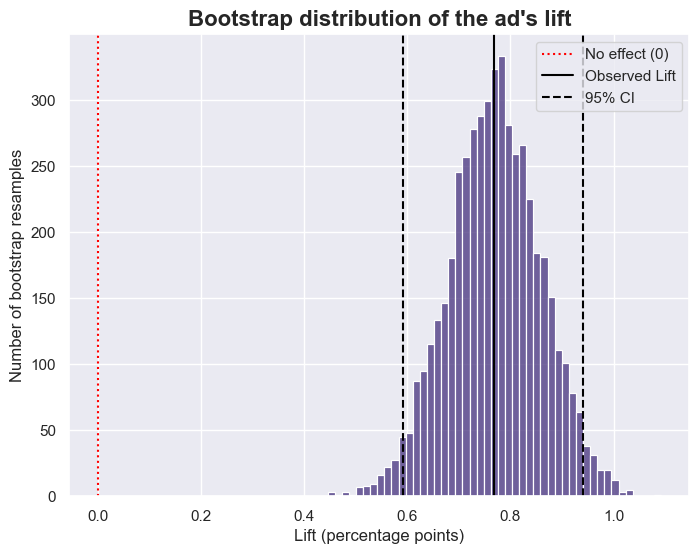

In [111]:
import matplotlib.pyplot as plt

lifts_pp = boot.bootstrap_distribution * 100

fig, ax = plt.subplots(figsize=(8,6))
sns.histplot(lifts_pp, ax=ax)
ax.set_title("Bootstrap distribution of the ad's lift", fontsize=16, fontweight='bold')
ax.set_xlabel("Lift (percentage points)")
ax.set_ylabel("Number of bootstrap resamples")

ax.axvline(x=0, color="red", linestyle=":", label="No effect (0)")
ax.axvline(x=lift*100, color="black", linestyle="-", label="Observed Lift")
ax.axvline(x=boot_low*100, color="black", linestyle="--", label="95% CI")
ax.axvline(x=boot_high*100, color="black", linestyle="--")
ax.legend()
plt.show();

## Logisitic Regression (check)

In [71]:
import statsmodels.formula.api as smf

In [72]:
df["converted_int"] = df["converted"].astype(int)   # logit needs 0/1 values, not True/False
logit = smf.logit('converted_int ~ C(test_group, Treatment(reference="psa"))', data=df).fit()

Optimization terminated successfully.
         Current function value: 0.117730
         Iterations 8


In [74]:
logit.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-4.0075,0.049,-81.393,0.000,-4.104,-3.911
"C(test_group, Treatment(reference=""psa""))[T.ad]",0.3661,0.050,7.329,0.000,0.268,0.464


In [76]:
np.exp(logit.params)

Intercept                                          0.018179
C(test_group, Treatment(reference="psa"))[T.ad]    1.442146
dtype: float64

In [ ]:
np.exp(logit.conf_int()) # gives 95% CI for each model coeff

,0,1
Intercept,0.016506,0.020020
"C(test_group, Treatment(reference=""psa""))[T.ad]",1.307641,1.590487


In [ ]:
print(np.exp(logit.params["Intercept"])) # intercept- odds of converting in psa group
print(rate_psa / (1 - rate_psa))

0.018178670360173444
0.018178670360110803


In [112]:
ame = logit.get_margeff(dummy=True).margeff[0]
print(f"average marginal effect: {ame * 100:.3f} pp")
print(f"z-test lift: {lift * 100:.3f} pp")

average marginal effect: 0.769 pp
z-test lift: 0.769 pp


The ad groups odds of converting are 1.44 time's that of the psa group. Also, once converted to pp, the model gives 0.77 pp, the same as the z test. This shows that the results from the earlier experiment was not a fluke, despite resampling and changing the data we got similar results for the CI.